# Medio-lateral GRF — final audited analysis (v6)

Final analysis decisions:
- Experimental unit = unique participant.
- Males only; all 104 eligible healthy male controls are included.
- Actual analyzed trials satisfy `SPEED == 2` (self-selected) and `SESSION_TYPE == 1`.
- 1:1 greedy nearest-neighbor matching on body mass, without replacement and without caliper.
- Side-specific comparisons: Healthy Left vs Knee Left; Healthy Right vs Knee Right.
- Preserve true RAW trial length: trim leading/trailing NaN padding; interpolate only internal gaps.
- No additional digital filtering before DWT.
- DWT: db4, level 4, fs=250 Hz, explicit symmetric boundary extension.
- DWT computed separately for every original trial.
- Primary wavelet metric = **Mean Squared Wavelet Coefficient (MSWC)** = `mean(c²)` within each subband.
- Repeated-trial MSWC values are averaged to one participant-level value per side/subband.
- Primary inference: Welch independent-samples t-test, Cohen's d with 95% bootstrap CI, and Holm correction across 10 primary tests.
- Sensitivity analysis: paired t-tests preserving matching pairs, with Holm correction across the same 10 comparisons.


## GaitRec metadata definitions — documentation correction (v5.2)

**This revision does not change the analytical pipeline or recalculate the results.** It corrects the interpretation/documentation of the GaitRec metadata used by the analysis.

- `SPEED = 1`: slow walking
- `SPEED = 2`: self-selected walking speed (**condition analyzed in this notebook**)
- `SPEED = 3`: fast walking
- `AFFECTED_SIDE = 0`: left
- `AFFECTED_SIDE = 1`: right
- `AFFECTED_SIDE = 2`: bilateral

Therefore, every analysis performed with `SPEED == 2` in this notebook refers to **self-selected walking speed**, not fast walking. Bilateral knee-dysfunction cases are excluded from the side-specific primary comparisons.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pywt
from scipy.stats import ttest_ind, ttest_rel, t
from IPython.display import display

RANDOM_SEED = 20260819
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 180)
print('PyWavelets:', pywt.__version__)



PyWavelets: 1.8.0


In [2]:
# 1. Locate and load source data
DATA_DIR = Path('.')

def first_match(patterns):
    for pattern in patterns:
        matches = sorted(DATA_DIR.glob(pattern))
        if matches:
            return matches[0]
    raise FileNotFoundError(f'No file matched: {patterns}')

metadata_path = first_match(['GRF_metadata*.csv'])
left_path = first_match(['GRF_F_ML_RAW_left*.csv'])
right_path = first_match(['GRF_F_ML_RAW_right*.csv'])

metadata = pd.read_csv(metadata_path)
grf_left = pd.read_csv(left_path)
grf_right = pd.read_csv(right_path)

print('Metadata:', metadata_path, metadata.shape)
print('Left RAW:', left_path, grf_left.shape)
print('Right RAW:', right_path, grf_right.shape)



Metadata: GRF_metadata.csv (8971, 20)
Left RAW: GRF_F_ML_RAW_left.csv (75732, 422)
Right RAW: GRF_F_ML_RAW_right.csv (75732, 408)


In [3]:
# 2. Analysis constants
FS = 250
WAVELET = 'db4'
LEVEL = 4
BOUNDARY_MODE = 'symmetric'
SPEED_CODE = 2
SESSION_TYPE_CODE = 1
SEX_CODE_MALE = 1
SIDE_MAP = {0: 'Left', 1: 'Right', 2: 'Both'}

signal_cols_left = sorted(
    [c for c in grf_left.columns if c.startswith('F_ML_RAW_')],
    key=lambda c: int(c.rsplit('_', 1)[1])
)
signal_cols_right = sorted(
    [c for c in grf_right.columns if c.startswith('F_ML_RAW_')],
    key=lambda c: int(c.rsplit('_', 1)[1])
)
print('Stored signal columns — left/right:', len(signal_cols_left), len(signal_cols_right))



Stored signal columns — left/right: 419 405


In [4]:
# 3. Eligible participant groups
eligible_sessions = metadata[
    (metadata['SPEED'] == SPEED_CODE) &
    (metadata['SESSION_TYPE'] == SESSION_TYPE_CODE)
].copy()

subjects = metadata.drop_duplicates(subset='SUBJECT_ID').copy()
subjects['SIDE_LABEL'] = subjects['AFFECTED_SIDE'].map(SIDE_MAP)
eligible_subjects = subjects[
    subjects['SUBJECT_ID'].isin(eligible_sessions['SUBJECT_ID'])
].copy()

healthy_male = eligible_subjects[
    (eligible_subjects['SEX'] == SEX_CODE_MALE) &
    (eligible_subjects['CLASS_LABEL'] == 'HC')
].dropna(subset=['BODY_MASS']).copy()

knee_left_male = eligible_subjects[
    (eligible_subjects['SEX'] == SEX_CODE_MALE) &
    (eligible_subjects['CLASS_LABEL'] == 'K') &
    (eligible_subjects['AFFECTED_SIDE'] == 0)
].dropna(subset=['BODY_MASS']).copy()

knee_right_male = eligible_subjects[
    (eligible_subjects['SEX'] == SEX_CODE_MALE) &
    (eligible_subjects['CLASS_LABEL'] == 'K') &
    (eligible_subjects['AFFECTED_SIDE'] == 1)
].dropna(subset=['BODY_MASS']).copy()

knee_bilateral_male = eligible_subjects[
    (eligible_subjects['SEX'] == SEX_CODE_MALE) &
    (eligible_subjects['CLASS_LABEL'] == 'K') &
    (eligible_subjects['AFFECTED_SIDE'] == 2)
].dropna(subset=['BODY_MASS']).copy()

print('Healthy male:', len(healthy_male))
print('Knee left male:', len(knee_left_male))
print('Knee right male:', len(knee_right_male))
print('Knee bilateral male:', len(knee_bilateral_male))



Healthy male: 104
Knee left male: 210
Knee right male: 160
Knee bilateral male: 5


In [5]:
# 4. Matching — all 104 eligible healthy controls; greedy 1:1 body-mass matching
N_HEALTHY = len(healthy_male)
assert N_HEALTHY == 104, f'Expected 104 eligible healthy males, found {N_HEALTHY}'
knee_reference_mass = pd.concat([
    knee_left_male['BODY_MASS'],
    knee_right_male['BODY_MASS']
], ignore_index=True)
target_mass = knee_reference_mass.median()

healthy_for_matching = healthy_male.copy()
healthy_for_matching['MASS_DISTANCE'] = (
    healthy_for_matching['BODY_MASS'] - target_mass
).abs()
# All 104 eligible healthy controls are retained. Sorting only defines the
# order of the greedy matching algorithm; it is not a control-selection step.
healthy_sample = (
    healthy_for_matching
    .sort_values('MASS_DISTANCE')
    .reset_index(drop=True)
    .drop(columns=['MASS_DISTANCE'])
    .copy()
)
healthy_sample['PAIR_ID'] = np.arange(1, len(healthy_sample) + 1)

def greedy_match_without_replacement(healthy_df, knee_df):
    available = knee_df.copy()
    matched = []
    if len(available) < len(healthy_df):
        raise ValueError('Knee pool smaller than healthy reference group')
    for _, h in healthy_df.iterrows():
        differences = (available['BODY_MASS'] - h['BODY_MASS']).abs()
        idx = differences.idxmin()
        k = available.loc[idx].copy()
        k['PAIR_ID'] = h['PAIR_ID']
        k['ABS_MASS_DIFFERENCE'] = abs(k['BODY_MASS'] - h['BODY_MASS'])
        matched.append(k)
        available = available.drop(index=idx)
    return pd.DataFrame(matched), available

knee_left_sample, knee_left_unused = greedy_match_without_replacement(
    healthy_sample, knee_left_male
)
knee_right_sample, knee_right_unused = greedy_match_without_replacement(
    healthy_sample, knee_right_male
)

matching_audit = pd.DataFrame([
    ['Healthy', len(healthy_male), len(healthy_sample), len(healthy_male)-len(healthy_sample), healthy_sample['BODY_MASS'].mean(), healthy_sample['BODY_MASS'].std(ddof=1)],
    ['Knee Left', len(knee_left_male), len(knee_left_sample), len(knee_left_male)-len(knee_left_sample), knee_left_sample['BODY_MASS'].mean(), knee_left_sample['BODY_MASS'].std(ddof=1)],
    ['Knee Right', len(knee_right_male), len(knee_right_sample), len(knee_right_male)-len(knee_right_sample), knee_right_sample['BODY_MASS'].mean(), knee_right_sample['BODY_MASS'].std(ddof=1)],
    ['Knee Bilateral (excluded)', len(knee_bilateral_male), 0, len(knee_bilateral_male), np.nan, np.nan],
], columns=['group','eligible_n','matched_n','not_in_final_matched_set_n','body_mass_mean','body_mass_sd'])
display(matching_audit)
print('Caliper: none')
print('Max absolute mass difference left:', knee_left_sample['ABS_MASS_DIFFERENCE'].max())
print('Max absolute mass difference right:', knee_right_sample['ABS_MASS_DIFFERENCE'].max())



,group,eligible_n,matched_n,not_in_final_matched_set_n,body_mass_mean,body_mass_sd
0,Healthy,104,104,0,82.344231,14.580122
1,Knee Left,210,104,106,81.980769,14.636907
2,Knee Right,160,104,56,82.846154,14.131257
3,Knee Bilateral (excluded),5,0,5,NaN,NaN


Caliper: none
Max absolute mass difference left: 6.299999999999983
Max absolute mass difference right: 30.6


In [6]:
# 5. Matching balance

def cohens_d_independent(x, y):
    x = np.asarray(x, float); y = np.asarray(y, float)
    nx, ny = len(x), len(y)
    vx, vy = x.var(ddof=1), y.var(ddof=1)
    pooled_sd = np.sqrt(((nx-1)*vx + (ny-1)*vy)/(nx+ny-2))
    if pooled_sd == 0:
        return np.nan
    return (y.mean()-x.mean())/pooled_sd

def mass_balance(control, knee, name):
    x = control['BODY_MASS'].to_numpy(float)
    y = knee['BODY_MASS'].to_numpy(float)
    stat = ttest_ind(x, y, equal_var=False)
    return {
        'comparison': name,
        'healthy_mean': x.mean(), 'healthy_sd': x.std(ddof=1),
        'knee_mean': y.mean(), 'knee_sd': y.std(ddof=1),
        'welch_t': stat.statistic, 'p_value': stat.pvalue,
        'cohens_d': cohens_d_independent(x, y)
    }

mass_balance_results = pd.DataFrame([
    mass_balance(healthy_sample, knee_left_sample, 'Healthy vs Knee Left'),
    mass_balance(healthy_sample, knee_right_sample, 'Healthy vs Knee Right')
])
display(mass_balance_results)



,comparison,healthy_mean,healthy_sd,knee_mean,knee_sd,welch_t,p_value,cohens_d
0,Healthy vs Knee Left,82.344231,14.580122,81.980769,14.636907,0.179413,0.85779,-0.024880
1,Healthy vs Knee Right,82.344231,14.580122,82.846154,14.131257,-0.252094,0.80122,0.034959


In [7]:
# 6. Attach metadata to RAW trials and enforce SPEED/SESSION_TYPE on analyzed trials
session_fields = [
    'SUBJECT_ID','SESSION_ID','SPEED','SESSION_TYPE','SEX',
    'CLASS_LABEL','AFFECTED_SIDE','BODY_MASS'
]
session_metadata = metadata[session_fields].drop_duplicates(['SUBJECT_ID','SESSION_ID'])

left_trials_all = grf_left.merge(
    session_metadata, on=['SUBJECT_ID','SESSION_ID'], how='left', validate='many_to_one'
)
right_trials_all = grf_right.merge(
    session_metadata, on=['SUBJECT_ID','SESSION_ID'], how='left', validate='many_to_one'
)

left_trials_condition = left_trials_all[
    (left_trials_all['SPEED'] == SPEED_CODE) &
    (left_trials_all['SESSION_TYPE'] == SESSION_TYPE_CODE)
].copy()
right_trials_condition = right_trials_all[
    (right_trials_all['SPEED'] == SPEED_CODE) &
    (right_trials_all['SESSION_TYPE'] == SESSION_TYPE_CODE)
].copy()

healthy_ids = set(healthy_sample['SUBJECT_ID'])
knee_left_ids = set(knee_left_sample['SUBJECT_ID'])
knee_right_ids = set(knee_right_sample['SUBJECT_ID'])



In [8]:
# 7. Preserve true RAW trial boundaries

def extract_true_trial(row, signal_cols):
    values = pd.to_numeric(row[signal_cols], errors='coerce').to_numpy(float)
    valid = np.flatnonzero(np.isfinite(values))
    if len(valid) == 0:
        return None
    values = values[valid[0]:valid[-1]+1]
    if np.isnan(values).any():
        values = pd.Series(values).interpolate(
            method='linear', limit_area='inside'
        ).to_numpy(float)
    if np.isnan(values).any():
        return None
    return values

def audit_trial_lengths(df, ids, signal_cols, group_name, side_name):
    subset = df[df['SUBJECT_ID'].isin(ids)]
    lengths, gaps = [], []
    valid_n = 0
    for _, row in subset.iterrows():
        raw = pd.to_numeric(row[signal_cols], errors='coerce').to_numpy(float)
        idx = np.flatnonzero(np.isfinite(raw))
        if len(idx) == 0:
            continue
        bounded = raw[idx[0]:idx[-1]+1]
        gaps.append(int(np.isnan(bounded).sum()))
        sig = extract_true_trial(row, signal_cols)
        if sig is None:
            continue
        valid_n += 1
        lengths.append(len(sig))
    return {
        'group': group_name, 'side': side_name,
        'raw_rows_in_condition': len(subset), 'valid_trials': valid_n,
        'min_samples': np.min(lengths), 'median_samples': np.median(lengths),
        'mean_samples': np.mean(lengths), 'max_samples': np.max(lengths),
        'trials_with_internal_missing_before_interpolation': int(np.sum(np.asarray(gaps)>0))
    }

trial_audit = pd.DataFrame([
    audit_trial_lengths(left_trials_condition, healthy_ids, signal_cols_left, 'Healthy', 'Left'),
    audit_trial_lengths(left_trials_condition, knee_left_ids, signal_cols_left, 'Knee Left', 'Left'),
    audit_trial_lengths(right_trials_condition, healthy_ids, signal_cols_right, 'Healthy', 'Right'),
    audit_trial_lengths(right_trials_condition, knee_right_ids, signal_cols_right, 'Knee Right', 'Right')
])
display(trial_audit)



,group,side,raw_rows_in_condition,valid_trials,min_samples,median_samples,mean_samples,max_samples,trials_with_internal_missing_before_interpolation
0,Healthy,Left,1276,1276,137,171.0,172.488245,232,0
1,Knee Left,Left,855,855,133,183.0,187.508772,310,0
2,Healthy,Right,1276,1276,136,172.0,173.161442,232,0
3,Knee Right,Right,859,859,145,186.0,188.232829,286,0


In [9]:
# 8. Trial-level DWT and Mean Squared Wavelet Coefficient (MSWC)
# MSWC = mean(square(coefficients)) = sum(c^2)/N_band
SUBBANDS_PYWT_ORDER = ['ylp4','yhp4','yhp3','yhp2','yhp1']
SUBBAND_FREQUENCIES = {
    'yhp1':'62.50–125.00 Hz', 'yhp2':'31.25–62.50 Hz',
    'yhp3':'15.63–31.25 Hz', 'yhp4':'7.81–15.63 Hz', 'ylp4':'0.00–7.81 Hz'
}

def mean_squared_wavelet_coefficient(signal):
    # Force a writable, C-contiguous buffer. Some PyWavelets/Cython builds
    # reject read-only NumPy views originating from pandas.
    signal_writable = np.array(signal, dtype=np.float64, copy=True, order='C')
    if not signal_writable.flags.writeable:
        signal_writable = signal_writable.copy()

    coeffs = pywt.wavedec(
        signal_writable, wavelet=WAVELET,
        level=LEVEL, mode=BOUNDARY_MODE
    )
    return {
        band: float(np.mean(np.square(coeff)))
        for band, coeff in zip(SUBBANDS_PYWT_ORDER, coeffs)
    }

def trial_level_mswc(df, ids, signal_cols, group_name, side_name):
    subset = df[df['SUBJECT_ID'].isin(ids)]
    rows, excluded = [], 0
    dec_len = pywt.Wavelet(WAVELET).dec_len
    for _, row in subset.iterrows():
        sig = extract_true_trial(row, signal_cols)
        if sig is None:
            excluded += 1; continue
        if pywt.dwt_max_level(len(sig), dec_len) < LEVEL:
            excluded += 1; continue
        mswc = mean_squared_wavelet_coefficient(sig)
        rows.append({
            'SUBJECT_ID': row['SUBJECT_ID'], 'SESSION_ID': row['SESSION_ID'],
            'TRIAL_ID': row['TRIAL_ID'], 'group': group_name, 'side': side_name,
            'n_samples': len(sig), **mswc
        })
    result = pd.DataFrame(rows)
    print(f'{group_name}/{side_name}: {len(result)} included, {excluded} excluded')
    return result

trial_mswc_healthy_left = trial_level_mswc(left_trials_condition, healthy_ids, signal_cols_left, 'Healthy', 'Left')
trial_mswc_knee_left = trial_level_mswc(left_trials_condition, knee_left_ids, signal_cols_left, 'Knee Left', 'Left')
trial_mswc_healthy_right = trial_level_mswc(right_trials_condition, healthy_ids, signal_cols_right, 'Healthy', 'Right')
trial_mswc_knee_right = trial_level_mswc(right_trials_condition, knee_right_ids, signal_cols_right, 'Knee Right', 'Right')



Healthy/Left: 1276 included, 0 excluded
Knee Left/Left: 855 included, 0 excluded
Healthy/Right: 1276 included, 0 excluded
Knee Right/Right: 859 included, 0 excluded


In [10]:
# 9. Aggregate repeated trials to one participant-level observation
MSWC_BANDS = ['ylp4','yhp4','yhp3','yhp2','yhp1']

def aggregate_subject_mswc(trial_df):
    agg_spec = {
        'n_trials': ('TRIAL_ID','count'),
        'mean_trial_samples': ('n_samples','mean')
    }
    for band in MSWC_BANDS:
        agg_spec[band] = (band,'mean')
    return trial_df.groupby(['SUBJECT_ID','group','side'], as_index=False).agg(**agg_spec)

subject_mswc_healthy_left = aggregate_subject_mswc(trial_mswc_healthy_left)
subject_mswc_knee_left = aggregate_subject_mswc(trial_mswc_knee_left)
subject_mswc_healthy_right = aggregate_subject_mswc(trial_mswc_healthy_right)
subject_mswc_knee_right = aggregate_subject_mswc(trial_mswc_knee_right)

for name, df in [
    ('Healthy Left',subject_mswc_healthy_left),('Knee Left',subject_mswc_knee_left),
    ('Healthy Right',subject_mswc_healthy_right),('Knee Right',subject_mswc_knee_right)
]:
    print(name, 'unique participants =', df['SUBJECT_ID'].nunique())



Healthy Left unique participants = 104
Knee Left unique participants = 104
Healthy Right unique participants = 104
Knee Right unique participants = 104


In [11]:
# 10. Statistical helpers

def welch_mean_difference_ci(x, y, alpha=0.05):
    x=np.asarray(x,float); y=np.asarray(y,float)
    nx,ny=len(x),len(y); vx=x.var(ddof=1); vy=y.var(ddof=1)
    diff=y.mean()-x.mean(); se=np.sqrt(vx/nx + vy/ny)
    df=(vx/nx + vy/ny)**2 / (((vx/nx)**2)/(nx-1) + ((vy/ny)**2)/(ny-1))
    crit=t.ppf(1-alpha/2,df)
    return diff, diff-crit*se, diff+crit*se, df

def bootstrap_cohens_d_ci(x, y, n_boot=5000, alpha=0.05, seed=RANDOM_SEED):
    x=np.asarray(x,float); y=np.asarray(y,float)
    rr=np.random.default_rng(seed)
    est=np.empty(n_boot)
    for i in range(n_boot):
        xb=rr.choice(x,size=len(x),replace=True)
        yb=rr.choice(y,size=len(y),replace=True)
        est[i]=cohens_d_independent(xb,yb)
    return np.nanpercentile(est,100*alpha/2), np.nanpercentile(est,100*(1-alpha/2))

def holm_adjust(p_values):
    p=np.asarray(p_values,float); m=len(p); order=np.argsort(p); sp=p[order]
    adj_sorted=np.empty(m); running=0.0
    for rank,pv in enumerate(sp):
        running=max(running,(m-rank)*pv)
        adj_sorted[rank]=min(running,1.0)
    adj=np.empty(m); adj[order]=adj_sorted
    return adj

def compare_band(healthy_df, knee_df, band, comparison):
    x=healthy_df[band].dropna().to_numpy(float)
    y=knee_df[band].dropna().to_numpy(float)
    stat=ttest_ind(x,y,equal_var=False,nan_policy='omit')
    diff,lo,hi,wdf=welch_mean_difference_ci(x,y)
    d=cohens_d_independent(x,y)
    seed=RANDOM_SEED + sum(ord(ch) for ch in (comparison+band))
    dlo,dhi=bootstrap_cohens_d_ci(x,y,seed=seed)
    return {
        'comparison':comparison,'band':band,'frequency_band':SUBBAND_FREQUENCIES[band],
        'healthy_n':len(x),'knee_n':len(y),
        'healthy_mean_mswc':x.mean(),'healthy_sd':x.std(ddof=1),
        'knee_mean_mswc':y.mean(),'knee_sd':y.std(ddof=1),
        'mean_difference_knee_minus_healthy':diff,
        'mean_difference_ci95_low':lo,'mean_difference_ci95_high':hi,
        'welch_t':stat.statistic,'welch_df':wdf,'p_raw':stat.pvalue,
        'cohens_d':d,'cohens_d_ci95_low':dlo,'cohens_d_ci95_high':dhi
    }



In [12]:
# 11. Corrected primary analysis
results=[]
for band in MSWC_BANDS:
    results.append(compare_band(subject_mswc_healthy_left,subject_mswc_knee_left,band,'Healthy Left vs Knee Left'))
for band in MSWC_BANDS:
    results.append(compare_band(subject_mswc_healthy_right,subject_mswc_knee_right,band,'Healthy Right vs Knee Right'))

corrected_stats=pd.DataFrame(results)
corrected_stats['p_holm_10']=holm_adjust(corrected_stats['p_raw'].to_numpy())
corrected_stats['significant_holm_0.05']=corrected_stats['p_holm_10']<0.05
band_order=pd.CategoricalDtype(categories=['yhp1','yhp2','yhp3','yhp4','ylp4'],ordered=True)
corrected_stats['band']=corrected_stats['band'].astype(band_order)
corrected_stats=corrected_stats.sort_values(['comparison','band']).reset_index(drop=True)
display(corrected_stats)



,comparison,band,frequency_band,healthy_n,knee_n,healthy_mean_mswc,healthy_sd,knee_mean_mswc,knee_sd,mean_difference_knee_minus_healthy,mean_difference_ci95_low,mean_difference_ci95_high,welch_t,welch_df,p_raw,cohens_d,cohens_d_ci95_low,cohens_d_ci95_high,p_holm_10,significant_holm_0.05
0,Healthy Left vs Knee Left,yhp1,62.50–125.00 Hz,104,104,0.213486,0.179977,0.167617,0.155358,-0.045870,-0.091840,0.000101,1.967483,201.697779,5.049839e-02,-0.272841,-0.540991,-0.008088,0.302990,False
1,Healthy Left vs Knee Left,yhp2,31.25–62.50 Hz,104,104,4.285118,4.061010,3.342563,3.710409,-0.942554,-2.006056,0.120947,1.747416,204.343170,8.206743e-02,-0.242323,-0.527377,0.018444,0.410337,False
2,Healthy Left vs Knee Left,yhp3,15.63–31.25 Hz,104,104,58.663924,43.377809,36.403559,34.735831,-22.260365,-33.006854,-11.513876,4.085031,196.605752,6.413164e-05,-0.566492,-0.862136,-0.293286,0.000513,True
3,Healthy Left vs Knee Left,yhp4,7.81–15.63 Hz,104,104,335.283846,200.597848,264.036337,202.216996,-71.247509,-126.313637,-16.181382,2.550894,205.986688,1.147066e-02,-0.353745,-0.632920,-0.080480,0.080295,False
4,Healthy Left vs Knee Left,ylp4,0.00–7.81 Hz,104,104,7503.168068,4203.884458,7682.891837,6029.981170,179.723769,-1242.370167,1601.817705,-0.249340,183.991001,8.033762e-01,0.034577,-0.251748,0.282190,1.000000,False
5,Healthy Right vs Knee Right,yhp1,62.50–125.00 Hz,104,104,0.197052,0.148446,0.198250,0.216125,0.001198,-0.049530,0.051925,-0.046580,182.491708,9.628991e-01,0.006459,-0.309078,0.249449,1.000000,False
6,Healthy Right vs Knee Right,yhp2,31.25–62.50 Hz,104,104,4.784563,4.998625,3.691561,4.069147,-1.093003,-2.339385,0.153380,1.729349,197.856546,8.530638e-02,-0.239818,-0.510074,0.022039,0.410337,False
7,Healthy Right vs Knee Right,yhp3,15.63–31.25 Hz,104,104,70.671876,54.816296,37.701892,37.105714,-32.969984,-45.777478,-20.162491,5.079443,181.011842,9.366527e-07,-0.704392,-0.987150,-0.444062,0.000009,True
8,Healthy Right vs Knee Right,yhp4,7.81–15.63 Hz,104,104,405.717029,249.417039,254.825941,216.103071,-150.891089,-214.699085,-87.083093,4.662809,201.905997,5.664560e-06,-0.646615,-0.980357,-0.346425,0.000051,True
9,Healthy Right vs Knee Right,ylp4,0.00–7.81 Hz,104,104,7862.468937,5069.391931,8294.807691,5660.903075,432.338754,-1036.847746,1901.525253,-0.580210,203.540886,5.624147e-01,0.080461,-0.188277,0.342374,1.000000,False


In [13]:
# 11.1 Sensitivity analysis — preserve 1:1 matching pairs

def paired_band_test(healthy_df, knee_df, healthy_match_df, knee_match_df, band, comparison):
    healthy_pairs = healthy_match_df[['SUBJECT_ID','PAIR_ID']].merge(
        healthy_df[['SUBJECT_ID',band]], on='SUBJECT_ID', how='inner'
    ).rename(columns={band:'healthy_mswc'})
    knee_pairs = knee_match_df[['SUBJECT_ID','PAIR_ID']].merge(
        knee_df[['SUBJECT_ID',band]], on='SUBJECT_ID', how='inner'
    ).rename(columns={band:'knee_mswc'})
    pairs = healthy_pairs[['PAIR_ID','healthy_mswc']].merge(
        knee_pairs[['PAIR_ID','knee_mswc']], on='PAIR_ID', how='inner', validate='one_to_one'
    ).dropna()
    stat = ttest_rel(pairs['knee_mswc'], pairs['healthy_mswc'])
    return {
        'comparison': comparison,
        'band': band,
        'frequency_band': SUBBAND_FREQUENCIES[band],
        'paired_n': len(pairs),
        'mean_paired_difference_knee_minus_healthy': float((pairs['knee_mswc']-pairs['healthy_mswc']).mean()),
        'paired_t': float(stat.statistic),
        'p_raw_paired': float(stat.pvalue),
    }

paired_results=[]
for band in MSWC_BANDS:
    paired_results.append(paired_band_test(
        subject_mswc_healthy_left, subject_mswc_knee_left,
        healthy_sample, knee_left_sample, band, 'Healthy Left vs Knee Left'
    ))
for band in MSWC_BANDS:
    paired_results.append(paired_band_test(
        subject_mswc_healthy_right, subject_mswc_knee_right,
        healthy_sample, knee_right_sample, band, 'Healthy Right vs Knee Right'
    ))

paired_sensitivity_stats=pd.DataFrame(paired_results)
paired_sensitivity_stats['p_holm_10_paired']=holm_adjust(
    paired_sensitivity_stats['p_raw_paired'].to_numpy()
)
paired_sensitivity_stats['significant_holm_0.05']=paired_sensitivity_stats['p_holm_10_paired']<0.05
paired_sensitivity_stats['band']=paired_sensitivity_stats['band'].astype(band_order)
paired_sensitivity_stats=paired_sensitivity_stats.sort_values(['comparison','band']).reset_index(drop=True)
display(paired_sensitivity_stats)


,comparison,band,frequency_band,paired_n,mean_paired_difference_knee_minus_healthy,paired_t,p_raw_paired,p_holm_10_paired,significant_holm_0.05
0,Healthy Left vs Knee Left,yhp1,62.50–125.00 Hz,104,-0.045870,-2.004723,0.047617,0.285701,False
1,Healthy Left vs Knee Left,yhp2,31.25–62.50 Hz,104,-0.942554,-1.655645,0.100838,0.403687,False
2,Healthy Left vs Knee Left,yhp3,15.63–31.25 Hz,104,-22.260365,-3.753003,0.000289,0.002314,True
3,Healthy Left vs Knee Left,yhp4,7.81–15.63 Hz,104,-71.247509,-2.798203,0.006135,0.042944,True
4,Healthy Left vs Knee Left,ylp4,0.00–7.81 Hz,104,179.723769,0.395533,0.693267,1.000000,False
5,Healthy Right vs Knee Right,yhp1,62.50–125.00 Hz,104,0.001198,0.045116,0.964102,1.000000,False
6,Healthy Right vs Knee Right,yhp2,31.25–62.50 Hz,104,-1.093003,-1.763761,0.080737,0.403687,False
7,Healthy Right vs Knee Right,yhp3,15.63–31.25 Hz,104,-32.969984,-5.103898,0.000002,0.000015,True
8,Healthy Right vs Knee Right,yhp4,7.81–15.63 Hz,104,-150.891089,-4.796980,0.000005,0.000049,True
9,Healthy Right vs Knee Right,ylp4,0.00–7.81 Hz,104,432.338754,0.913208,0.363266,1.000000,False


In [14]:
# 12. Submitted Table II vs corrected inference
# Raw magnitudes are NOT directly comparable because submitted values used absolute energy,
# while corrected values use Mean Squared Wavelet Coefficient.
submitted=pd.DataFrame([
    ['Left','ylp4',103603,66847,127019,105467,0.0575,0.265],
    ['Left','yhp4',2785,2559,3166,2813,0.3088,0.142],
    ['Left','yhp3',1209,1010,716,747,0.0001,-0.555],
    ['Left','yhp2',66.45,82.78,58.80,76.86,0.4904,-0.096],
    ['Left','yhp1',2.82,3.26,2.15,2.61,0.1027,-0.227],
    ['Right','ylp4',103603,66847,134234,83326,0.0039,0.406],
    ['Right','yhp4',2785,2559,3425,2843,0.0896,0.237],
    ['Right','yhp3',1209,1010,638,691,0.0001,-0.659],
    ['Right','yhp2',66.45,82.78,52.96,67.39,0.1988,-0.179],
    ['Right','yhp1',2.82,3.26,2.32,3.08,0.2577,-0.157],
],columns=['side','band','submitted_healthy_mean_absolute_energy','submitted_healthy_sd','submitted_knee_mean_absolute_energy','submitted_knee_sd','submitted_p_raw','submitted_cohens_d'])

cc=corrected_stats.copy()
cc['side']=np.where(cc['comparison'].str.contains('Left'),'Left','Right')
comparison_table=submitted.merge(cc[[
    'side','band','healthy_mean_mswc','knee_mean_mswc',
    'p_raw','p_holm_10','cohens_d','cohens_d_ci95_low','cohens_d_ci95_high','significant_holm_0.05'
]],on=['side','band'],how='left')
comparison_table['submitted_direction']=np.sign(
    comparison_table['submitted_knee_mean_absolute_energy']-comparison_table['submitted_healthy_mean_absolute_energy']
)
comparison_table['corrected_direction']=np.sign(
    comparison_table['knee_mean_mswc']-comparison_table['healthy_mean_mswc']
)
comparison_table['direction_preserved']=comparison_table['submitted_direction']==comparison_table['corrected_direction']
display(comparison_table)



,side,band,submitted_healthy_mean_absolute_energy,submitted_healthy_sd,submitted_knee_mean_absolute_energy,submitted_knee_sd,submitted_p_raw,submitted_cohens_d,healthy_mean_mswc,knee_mean_mswc,p_raw,p_holm_10,cohens_d,cohens_d_ci95_low,cohens_d_ci95_high,significant_holm_0.05,submitted_direction,corrected_direction,direction_preserved
0,Left,ylp4,103603.00,66847.00,127019.00,105467.00,0.0575,0.265,7503.168068,7682.891837,8.033762e-01,1.000000,0.034577,-0.251748,0.282190,False,1.0,1.0,True
1,Left,yhp4,2785.00,2559.00,3166.00,2813.00,0.3088,0.142,335.283846,264.036337,1.147066e-02,0.080295,-0.353745,-0.632920,-0.080480,False,1.0,-1.0,False
2,Left,yhp3,1209.00,1010.00,716.00,747.00,0.0001,-0.555,58.663924,36.403559,6.413164e-05,0.000513,-0.566492,-0.862136,-0.293286,True,-1.0,-1.0,True
3,Left,yhp2,66.45,82.78,58.80,76.86,0.4904,-0.096,4.285118,3.342563,8.206743e-02,0.410337,-0.242323,-0.527377,0.018444,False,-1.0,-1.0,True
4,Left,yhp1,2.82,3.26,2.15,2.61,0.1027,-0.227,0.213486,0.167617,5.049839e-02,0.302990,-0.272841,-0.540991,-0.008088,False,-1.0,-1.0,True
5,Right,ylp4,103603.00,66847.00,134234.00,83326.00,0.0039,0.406,7862.468937,8294.807691,5.624147e-01,1.000000,0.080461,-0.188277,0.342374,False,1.0,1.0,True
6,Right,yhp4,2785.00,2559.00,3425.00,2843.00,0.0896,0.237,405.717029,254.825941,5.664560e-06,0.000051,-0.646615,-0.980357,-0.346425,True,1.0,-1.0,False
7,Right,yhp3,1209.00,1010.00,638.00,691.00,0.0001,-0.659,70.671876,37.701892,9.366527e-07,0.000009,-0.704392,-0.987150,-0.444062,True,-1.0,-1.0,True
8,Right,yhp2,66.45,82.78,52.96,67.39,0.1988,-0.179,4.784563,3.691561,8.530638e-02,0.410337,-0.239818,-0.510074,0.022039,False,-1.0,-1.0,True
9,Right,yhp1,2.82,3.26,2.32,3.08,0.2577,-0.157,0.197052,0.198250,9.628991e-01,1.000000,0.006459,-0.309078,0.249449,False,-1.0,1.0,False


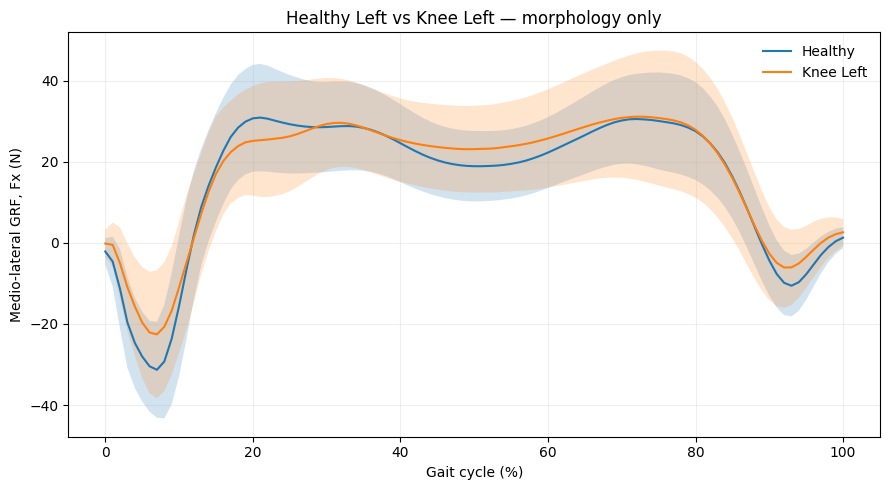

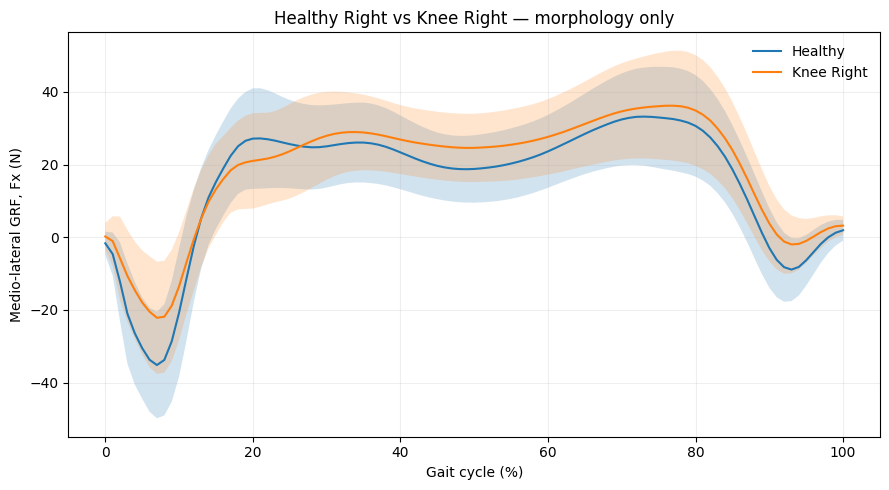

In [15]:
# 13. Visualization only — time normalization does NOT feed DWT statistics

def resample_to_percent(signal,n_points=101):
    src=np.linspace(0,100,len(signal)); dst=np.linspace(0,100,n_points)
    return np.interp(dst,src,signal)

def subject_normalized_curves(df,ids,signal_cols,n_points=101):
    subset=df[df['SUBJECT_ID'].isin(ids)]
    bucket={}
    for _,row in subset.iterrows():
        sig=extract_true_trial(row,signal_cols)
        if sig is None: continue
        bucket.setdefault(row['SUBJECT_ID'],[]).append(resample_to_percent(sig,n_points))
    matrix=np.vstack([np.mean(np.vstack(v),axis=0) for v in bucket.values()])
    return matrix

def plot_group_curves(healthy_matrix,knee_matrix,title,knee_label):
    x=np.linspace(0,100,healthy_matrix.shape[1])
    mh=healthy_matrix.mean(axis=0); sh=healthy_matrix.std(axis=0,ddof=1)
    mk=knee_matrix.mean(axis=0); sk=knee_matrix.std(axis=0,ddof=1)
    plt.figure(figsize=(9,5))
    plt.plot(x,mh,label='Healthy'); plt.fill_between(x,mh-sh,mh+sh,alpha=.2)
    plt.plot(x,mk,label=knee_label); plt.fill_between(x,mk-sk,mk+sk,alpha=.2)
    plt.xlabel('Gait cycle (%)'); plt.ylabel('Medio-lateral GRF, Fx (N)')
    plt.title(title); plt.legend(frameon=False); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

curve_hl=subject_normalized_curves(left_trials_condition,healthy_ids,signal_cols_left)
curve_kl=subject_normalized_curves(left_trials_condition,knee_left_ids,signal_cols_left)
curve_hr=subject_normalized_curves(right_trials_condition,healthy_ids,signal_cols_right)
curve_kr=subject_normalized_curves(right_trials_condition,knee_right_ids,signal_cols_right)
plot_group_curves(curve_hl,curve_kl,'Healthy Left vs Knee Left — morphology only','Knee Left')
plot_group_curves(curve_hr,curve_kr,'Healthy Right vs Knee Right — morphology only','Knee Right')



In [16]:
# 14. Export results
OUTPUT_DIR=Path('audit_outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
matching_audit.to_csv(OUTPUT_DIR/'matching_audit.csv',index=False)
trial_audit.to_csv(OUTPUT_DIR/'trial_audit.csv',index=False)
pd.concat([
    subject_mswc_healthy_left,subject_mswc_knee_left,
    subject_mswc_healthy_right,subject_mswc_knee_right
],ignore_index=True).to_csv(OUTPUT_DIR/'corrected_subject_mswc.csv',index=False)
corrected_stats.to_csv(OUTPUT_DIR/'corrected_statistics.csv',index=False)
paired_sensitivity_stats.to_csv(OUTPUT_DIR/'paired_sensitivity_statistics.csv',index=False)
comparison_table.to_csv(OUTPUT_DIR/'submitted_vs_corrected_comparison.csv',index=False)
print('Exported to',OUTPUT_DIR.resolve())


Exported to C:\Users\nog_l\OneDrive\1-Documentos\Github_repositórios\Artigo_analise_medio_lateral\Analise medio lateral\audit_outputs


# 17. Publication-ready outputs — FINAL v6

This section does **not alter the analytical pipeline or statistical results**. It only prepares the final figures and tables for the revised manuscript.

Outputs:

- **Figure 2:** one combined figure with two rows (left- and right-knee comparisons) and the five DWT subbands.
- **Figure 3:** one combined figure with side-specific legends and Holm-adjusted significance markers.
- **Table I:** body-mass balance after matching.
- **Table II:** unified corrected statistics table without side-specific `NaN` columns.

The final figures are exported as PNG (600 dpi) and SVG to:
`audit_outputs/publication_ready_FINAL_v6/`.

In [17]:
# 17.1 Output folder and formatting helpers

PUB_DIR_V4 = OUTPUT_DIR / "publication_ready_FINAL_v6"
PUB_DIR_V4.mkdir(parents=True, exist_ok=True)

def p_format(p):
    if pd.isna(p):
        return ""
    if p < 0.0001:
        return "<0.0001"
    return f"{p:.4f}"

def ci_text(lo, hi, digits=2):
    return f"[{lo:.{digits}f}, {hi:.{digits}f}]"

def mean_sd_text(mean, sd, digits=2):
    return f"{mean:.{digits}f} ± {sd:.{digits}f}"

def holm_p_label(p_adj):
    """Compact manuscript label for Holm-adjusted p-values."""
    if pd.isna(p_adj):
        return ""
    if p_adj < 0.0001:
        return r"$p_{Holm}<0.0001$"
    return rf"$p_{{Holm}}={p_adj:.4f}$"


In [18]:
# 17.2 TABLE I — body-mass balance after 1:1 nearest-neighbor matching

table1_rows = []

for _, row in mass_balance_results.iterrows():
    is_left = "Left" in row["comparison"]
    knee_label = "Left knee" if is_left else "Right knee"
    knee_df = knee_left_sample if is_left else knee_right_sample

    table1_rows.append({
        "Comparison": f"Healthy × {knee_label}",
        "Group": "Healthy",
        "N": len(healthy_sample),
        "Body mass, mean ± SD (kg)": mean_sd_text(
            healthy_sample["BODY_MASS"].mean(),
            healthy_sample["BODY_MASS"].std(ddof=1)
        ),
        "p-value": p_format(row["p_value"]),
        "Cohen's d": f'{row["cohens_d"]:.3f}',
    })

    table1_rows.append({
        "Comparison": "",
        "Group": knee_label,
        "N": len(knee_df),
        "Body mass, mean ± SD (kg)": mean_sd_text(
            knee_df["BODY_MASS"].mean(),
            knee_df["BODY_MASS"].std(ddof=1)
        ),
        "p-value": "",
        "Cohen's d": "",
    })

table1_publication_v4 = pd.DataFrame(table1_rows)

display(table1_publication_v4)

table1_publication_v4.to_csv(
    PUB_DIR_V4 / "Table_I_body_mass_matching.csv",
    index=False,
)

,Comparison,Group,N,"Body mass, mean ± SD (kg)",p-value,Cohen's d
0,Healthy × Left knee,Healthy,104,82.34 ± 14.58,0.8578,-0.025
1,,Left knee,104,81.98 ± 14.64,,
2,Healthy × Right knee,Healthy,104,82.34 ± 14.58,0.8012,0.035
3,,Right knee,104,82.85 ± 14.13,,


In [19]:
# 17.3 TABLE II — unified Mean Squared Wavelet Coefficient statistics
#
# One common "Knee dysfunction" column is used for both sides, eliminating
# the blank/NaN columns in the previous publication table.

present_order = ["ylp4", "yhp4", "yhp3", "yhp2", "yhp1"]
table2_rows = []

for side_label, comparison_name in [
    ("Left", "Healthy Left vs Knee Left"),
    ("Right", "Healthy Right vs Knee Right"),
]:
    sub = corrected_stats[
        corrected_stats["comparison"] == comparison_name
    ].copy()

    sub["present_order"] = sub["band"].astype(str).map(
        {b: i for i, b in enumerate(present_order)}
    )
    sub = sub.sort_values("present_order")

    for _, r in sub.iterrows():
        table2_rows.append({
            "Side": side_label,
            "Band": str(r["band"]),
            "Frequency band": r["frequency_band"],
            "Healthy MSWC, mean ± SD": mean_sd_text(
                r["healthy_mean_mswc"],
                r["healthy_sd"]
            ),
            "Knee dysfunction MSWC, mean ± SD": mean_sd_text(
                r["knee_mean_mswc"],
                r["knee_sd"]
            ),
            "Mean difference (knee - healthy), 95% CI":
                f'{r["mean_difference_knee_minus_healthy"]:.2f} '
                f'{ci_text(r["mean_difference_ci95_low"], r["mean_difference_ci95_high"])}',
            "Raw p": p_format(r["p_raw"]),
            "Holm-adjusted p": p_format(r["p_holm_10"]),
            "Cohen's d, 95% CI":
                f'{r["cohens_d"]:.3f} '
                f'{ci_text(r["cohens_d_ci95_low"], r["cohens_d_ci95_high"], digits=3)}',
        })

table2_publication_v4 = pd.DataFrame(table2_rows)

display(table2_publication_v4)

table2_publication_v4.to_csv(
    PUB_DIR_V4 / "Table_II_MSWC_statistics.csv",
    index=False,
)

,Side,Band,Frequency band,"Healthy MSWC, mean ± SD","Knee dysfunction MSWC, mean ± SD","Mean difference (knee - healthy), 95% CI",Raw p,Holm-adjusted p,"Cohen's d, 95% CI"
0,Left,ylp4,0.00–7.81 Hz,7503.17 ± 4203.88,7682.89 ± 6029.98,"179.72 [-1242.37, 1601.82]",0.8034,1.0000,"0.035 [-0.252, 0.282]"
1,Left,yhp4,7.81–15.63 Hz,335.28 ± 200.60,264.04 ± 202.22,"-71.25 [-126.31, -16.18]",0.0115,0.0803,"-0.354 [-0.633, -0.080]"
2,Left,yhp3,15.63–31.25 Hz,58.66 ± 43.38,36.40 ± 34.74,"-22.26 [-33.01, -11.51]",<0.0001,0.0005,"-0.566 [-0.862, -0.293]"
3,Left,yhp2,31.25–62.50 Hz,4.29 ± 4.06,3.34 ± 3.71,"-0.94 [-2.01, 0.12]",0.0821,0.4103,"-0.242 [-0.527, 0.018]"
4,Left,yhp1,62.50–125.00 Hz,0.21 ± 0.18,0.17 ± 0.16,"-0.05 [-0.09, 0.00]",0.0505,0.3030,"-0.273 [-0.541, -0.008]"
5,Right,ylp4,0.00–7.81 Hz,7862.47 ± 5069.39,8294.81 ± 5660.90,"432.34 [-1036.85, 1901.53]",0.5624,1.0000,"0.080 [-0.188, 0.342]"
6,Right,yhp4,7.81–15.63 Hz,405.72 ± 249.42,254.83 ± 216.10,"-150.89 [-214.70, -87.08]",<0.0001,<0.0001,"-0.647 [-0.980, -0.346]"
7,Right,yhp3,15.63–31.25 Hz,70.67 ± 54.82,37.70 ± 37.11,"-32.97 [-45.78, -20.16]",<0.0001,<0.0001,"-0.704 [-0.987, -0.444]"
8,Right,yhp2,31.25–62.50 Hz,4.78 ± 5.00,3.69 ± 4.07,"-1.09 [-2.34, 0.15]",0.0853,0.4103,"-0.240 [-0.510, 0.022]"
9,Right,yhp1,62.50–125.00 Hz,0.20 ± 0.15,0.20 ± 0.22,"0.00 [-0.05, 0.05]",0.9629,1.0000,"0.006 [-0.309, 0.249]"


c:\Users\nog_l\AppData\Local\Programs\Python\Python313\Lib\site-packages\pywt\_multilevel.py:43: UserWarning: Level value of 4 is too high: all coefficients will experience boundary effects.
  warnings.warn(


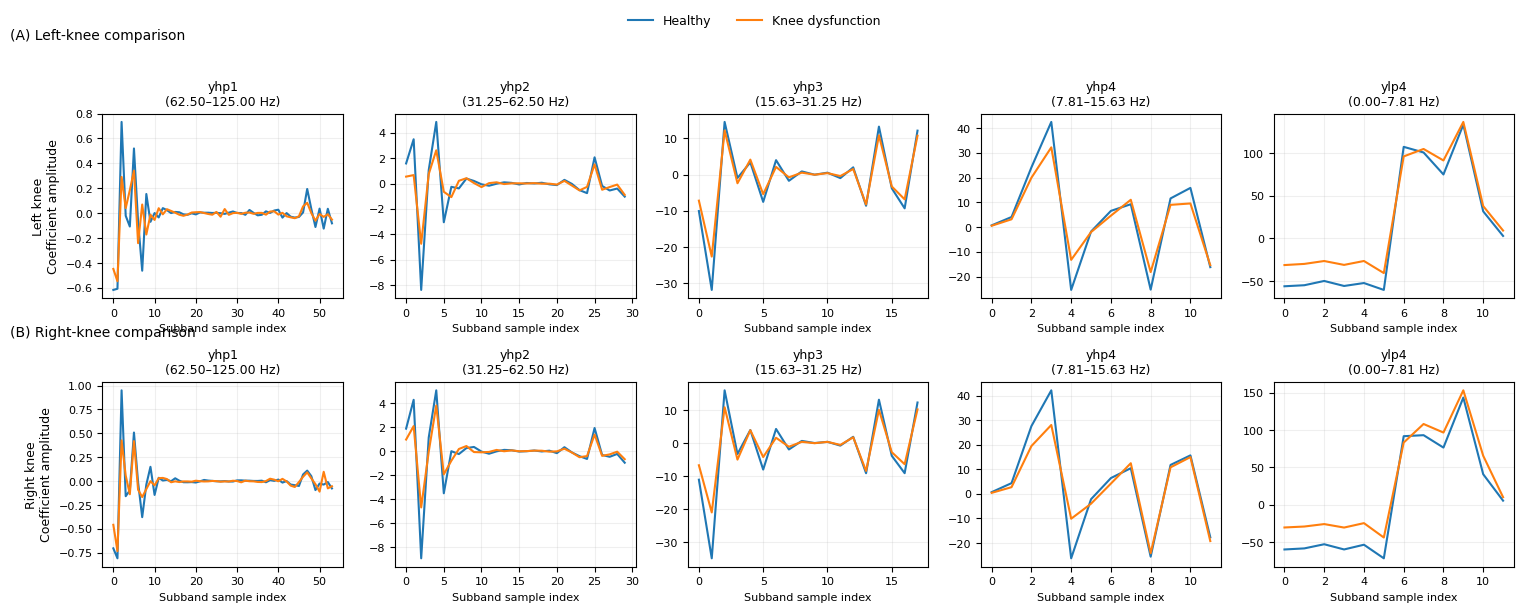

Saved: audit_outputs\publication_ready_FINAL_v6\Figure_2_DWT_combined.png
Saved: audit_outputs\publication_ready_FINAL_v6\Figure_2_DWT_combined.svg


In [20]:
# 17.4 FIGURE 2 — combined representative DWT decomposition
#
# IMPORTANT:
# This figure is illustrative. Statistical inference is based on the
# non-time-normalized trial-level DWT described in Sections 9–12.
#
# Here, time-normalized group-mean curves are decomposed only to visually
# illustrate the five wavelet subbands.

def group_mean_curve(matrix):
    return np.asarray(matrix, dtype=np.float64).mean(axis=0)

def dwt_components(signal):
    signal = np.array(signal, dtype=np.float64, copy=True, order="C")
    coeffs = pywt.wavedec(
        signal,
        wavelet=WAVELET,
        level=LEVEL,
        mode=BOUNDARY_MODE,
    )
    return dict(zip(SUBBANDS_PYWT_ORDER, coeffs))

mean_hl = group_mean_curve(curve_hl)
mean_kl = group_mean_curve(curve_kl)
mean_hr = group_mean_curve(curve_hr)
mean_kr = group_mean_curve(curve_kr)

components = {
    "Left": {
        "Healthy": dwt_components(mean_hl),
        "Knee": dwt_components(mean_kl),
        "Knee label": "Knee Left",
    },
    "Right": {
        "Healthy": dwt_components(mean_hr),
        "Knee": dwt_components(mean_kr),
        "Knee label": "Knee Right",
    },
}

bands_fig2 = ["yhp1", "yhp2", "yhp3", "yhp4", "ylp4"]

fig, axes = plt.subplots(
    2, 5,
    figsize=(15.5, 6.2),
)

legend_handles = None

for row_idx, side in enumerate(["Left", "Right"]):
    for col_idx, band in enumerate(bands_fig2):
        ax = axes[row_idx, col_idx]

        h = components[side]["Healthy"][band]
        k = components[side]["Knee"][band]

        line_healthy, = ax.plot(np.arange(len(h)), h, label="Healthy")
        line_knee, = ax.plot(np.arange(len(k)), k, label="Knee dysfunction")

        if legend_handles is None:
            legend_handles = [line_healthy, line_knee]

        ax.set_title(
            f"{band}\n({SUBBAND_FREQUENCIES[band]})",
            fontsize=9,
        )
        ax.set_xlabel("Subband sample index", fontsize=8)
        if col_idx == 0:
            ax.set_ylabel(
                f"{side} knee\nCoefficient amplitude",
                fontsize=9,
            )
        ax.tick_params(labelsize=8)
        ax.grid(alpha=0.2)

fig.legend(
    legend_handles,
    ["Healthy", "Knee dysfunction"],
    loc="upper center",
    bbox_to_anchor=(0.5, 1.01),
    ncol=2,
    frameon=False,
    fontsize=9,
)

fig.text(
    0.02, 0.97, "(A) Left-knee comparison",
    ha="left", va="top", fontsize=10
)
fig.text(
    0.02, 0.49, "(B) Right-knee comparison",
    ha="left", va="top", fontsize=10
)

fig.tight_layout(rect=[0.02, 0.02, 1, 0.91])

fig2_png = PUB_DIR_V4 / "Figure_2_DWT_combined.png"
fig2_svg = PUB_DIR_V4 / "Figure_2_DWT_combined.svg"

fig.savefig(fig2_png, dpi=600, bbox_inches="tight")
fig.savefig(fig2_svg, bbox_inches="tight")
plt.show()

print("Saved:", fig2_png)
print("Saved:", fig2_svg)

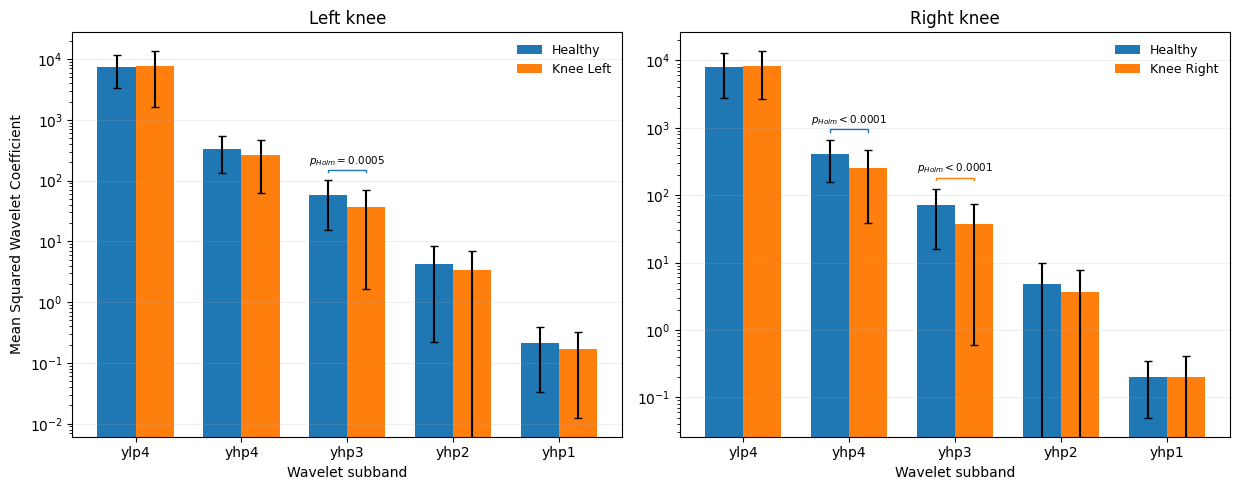

Saved: audit_outputs\publication_ready_FINAL_v6\Figure_3_MSWC.png
Saved: audit_outputs\publication_ready_FINAL_v6\Figure_3_MSWC.svg


In [21]:
# 17.5 FIGURE 3 — combined Mean Squared Wavelet Coefficient
#
# Bars = participant-level mean ± SD.
# Significant comparisons are labeled with their Holm-adjusted p-values
# across the 10 primary comparisons.
#
# Each panel has its own side-specific legend so that the right panel is
# correctly labeled "Knee Right".

def get_side_mswc_frames(side):
    if side == "Left":
        return (
            subject_mswc_healthy_left,
            subject_mswc_knee_left,
            "Knee Left",
            "Healthy Left vs Knee Left",
        )
    return (
        subject_mswc_healthy_right,
        subject_mswc_knee_right,
        "Knee Right",
        "Healthy Right vs Knee Right",
    )

def draw_mswc_panel(ax, side):
    healthy_df, knee_df, knee_label, comparison_name = get_side_mswc_frames(side)

    bands = ["ylp4", "yhp4", "yhp3", "yhp2", "yhp1"]
    healthy_means = np.array([healthy_df[b].mean() for b in bands])
    healthy_sds = np.array([healthy_df[b].std(ddof=1) for b in bands])
    knee_means = np.array([knee_df[b].mean() for b in bands])
    knee_sds = np.array([knee_df[b].std(ddof=1) for b in bands])

    x = np.arange(len(bands))
    width = 0.36

    ax.bar(
        x - width/2,
        healthy_means,
        width,
        yerr=healthy_sds,
        capsize=3,
        label="Healthy",
    )
    ax.bar(
        x + width/2,
        knee_means,
        width,
        yerr=knee_sds,
        capsize=3,
        label=knee_label,
    )

    ax.set_yscale("log")
    ax.set_xticks(x)
    ax.set_xticklabels(bands)
    ax.set_xlabel("Wavelet subband")
    ax.set_title(f"{side} knee")
    ax.grid(axis="y", alpha=0.2)
    ax.legend(frameon=False, fontsize=9)

    stats_side = corrected_stats[
        corrected_stats["comparison"] == comparison_name
    ].copy()

    for i, band in enumerate(bands):
        row = stats_side[
            stats_side["band"].astype(str) == band
        ].iloc[0]

        if row["p_holm_10"] < 0.05:
            upper = max(
                healthy_means[i] + healthy_sds[i],
                knee_means[i] + knee_sds[i],
            )
            y = upper * 1.45
            ax.plot(
                [i-width/2, i-width/2, i+width/2, i+width/2],
                [y/1.08, y, y, y/1.08],
                linewidth=1,
            )
            ax.text(
                i,
                y * 1.08,
                holm_p_label(row["p_holm_10"]),
                ha="center",
                va="bottom",
                fontsize=7.5,
            )

fig, axes = plt.subplots(
    1, 2,
    figsize=(12.5, 5.0),
)

draw_mswc_panel(axes[0], "Left")
draw_mswc_panel(axes[1], "Right")

axes[0].set_ylabel(
    "Mean Squared Wavelet Coefficient"
)

fig.tight_layout()

fig3_png = PUB_DIR_V4 / "Figure_3_MSWC.png"
fig3_svg = PUB_DIR_V4 / "Figure_3_MSWC.svg"

fig.savefig(fig3_png, dpi=600, bbox_inches="tight")
fig.savefig(fig3_svg, bbox_inches="tight")
plt.show()

print("Saved:", fig3_png)
print("Saved:", fig3_svg)

In [22]:
# 17.6 Manuscript-ready figure captions

figure_2_caption = (
    "Fig. 2. Representative four-level discrete wavelet transform (DWT; db4) "
    "decomposition of the time-normalized group-mean medio-lateral ground "
    "reaction force (Fx) for (A) healthy-left versus left-knee dysfunction "
    "and (B) healthy-right versus right-knee dysfunction. The panels show "
    "the detail coefficients yhp1-yhp4 and the approximation coefficient ylp4. "
    "This decomposition is provided for visual illustration; quantitative "
    "statistical analyses were performed on non-time-normalized individual "
    "trials before participant-level aggregation."
)

figure_3_caption = (
    "Fig. 3. Participant-level Mean Squared Wavelet Coefficient (MSWC; mean ± SD) for the "
    "five DWT subbands in the left- and right-knee comparisons. Normalized "
    "energy was calculated as the mean squared coefficient amplitude within "
    "each band. Statistically significant comparisons are labeled with their "
    "Holm-adjusted p-values after correction across the 10 primary comparisons "
    "(five wavelet bands × two sides). The y-axis is displayed on a logarithmic "
    "scale because MSWC values span several orders of magnitude."
)

print(figure_2_caption)
print()
print(figure_3_caption)

with open(PUB_DIR_V4 / "Figure_captions.txt", "w", encoding="utf-8") as f:
    f.write(figure_2_caption + "\n\n" + figure_3_caption)

Fig. 2. Representative four-level discrete wavelet transform (DWT; db4) decomposition of the time-normalized group-mean medio-lateral ground reaction force (Fx) for (A) healthy-left versus left-knee dysfunction and (B) healthy-right versus right-knee dysfunction. The panels show the detail coefficients yhp1-yhp4 and the approximation coefficient ylp4. This decomposition is provided for visual illustration; quantitative statistical analyses were performed on non-time-normalized individual trials before participant-level aggregation.

Fig. 3. Participant-level Mean Squared Wavelet Coefficient (MSWC; mean ± SD) for the five DWT subbands in the left- and right-knee comparisons. Normalized energy was calculated as the mean squared coefficient amplitude within each band. Statistically significant comparisons are labeled with their Holm-adjusted p-values after correction across the 10 primary comparisons (five wavelet bands × two sides). The y-axis is displayed on a logarithmic scale because 

In [ ]:
# 17.7 Export Tables I and II to one Excel workbook

excel_path_v4 = PUB_DIR_V4 / "Tables_I_II_FINAL_v6.xlsx"

with pd.ExcelWriter(excel_path_v4) as writer:
    table1_publication_v4.to_excel(
        writer,
        sheet_name="Table I - Matching",
        index=False,
    )
    table2_publication_v4.to_excel(
        writer,
        sheet_name="Table II - Wavelet",
        index=False,
    )

print("Publication-ready v4 outputs:")
for f in sorted(PUB_DIR_V4.glob("*")):
    print("-", f.name)

Publication-ready v4 outputs:
- Figure_2_DWT_combined.png
- Figure_2_DWT_combined.svg
- Figure_3_MSWC.png
- Figure_3_MSWC.svg
- Figure_captions.txt
- Table_I_body_mass_matching.csv
- Table_II_MSWC_statistics.csv
- Tables_I_II_FINAL_v6.xlsx


: 